<a href="https://colab.research.google.com/github/RaviParkhe/LinearRegression-Activity1-AD3255/blob/main/Multi_Linear_Regression_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🏥 Medical Insurance Cost Prediction using Multiple Linear Regression

## Problem Statement
Health insurance providers and hospitals need to understand which lifestyle and demographic factors drive up medical expenses. This helps in:
- **Accurate policy pricing** for insurance companies
- **Preventative care program design** for hospitals
- **Cost transparency** for patients

## Objective
Build a **Multiple Linear Regression** model to predict annual medical insurance charges based on demographic and lifestyle factors such as age, BMI, smoking status, number of children, and region.

## Dataset
**Medical Cost Personal Dataset** from Kaggle (`mirichoi0218/insurance`)
- 1,338 records with 7 columns
- Target variable: `charges` (Annual medical bills in USD)

---
## Step 1: Download Dataset from Kaggle

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mirichoi0218/insurance")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'insurance' dataset.
Path to dataset files: /kaggle/input/insurance


---
## Step 2: Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


---
## Step 3: Load & Explore the Dataset

In [ ]:
# Load the dataset
df = pd.read_csv(os.path.join(path, 'insurance.csv'))

print("First 5 rows of the dataset:")
print(df.head())

First 5 rows of the dataset:
   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520


In [ ]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
print(df.describe())

Dataset Shape: (1338, 7)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB
None

Missing Values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Statistical Summary:
               age          bmi     children       charges
count  1338.000000  1338.000000  1338.000000   1338.000000
mean     39.207025    30.663397     1.094918  13270.422265
std      14.049960     6.098187     1.205493  12110.011237
min      18.000000    15.960000     0.0000

In [ ]:
print("\nData Types:")
print(df.dtypes)

print("\nUnique values in categorical columns:")
for col in df.select_dtypes(include='object').columns:
    print(f"  {col}: {df[col].unique()} ({df[col].nunique()} unique)")


Data Types:
age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object

Unique values in categorical columns:
  sex: ['female' 'male'] (2 unique)
  smoker: ['yes' 'no'] (2 unique)
  region: ['southwest' 'southeast' 'northwest' 'northeast'] (4 unique)


---
## Step 4: Exploratory Data Analysis (EDA)

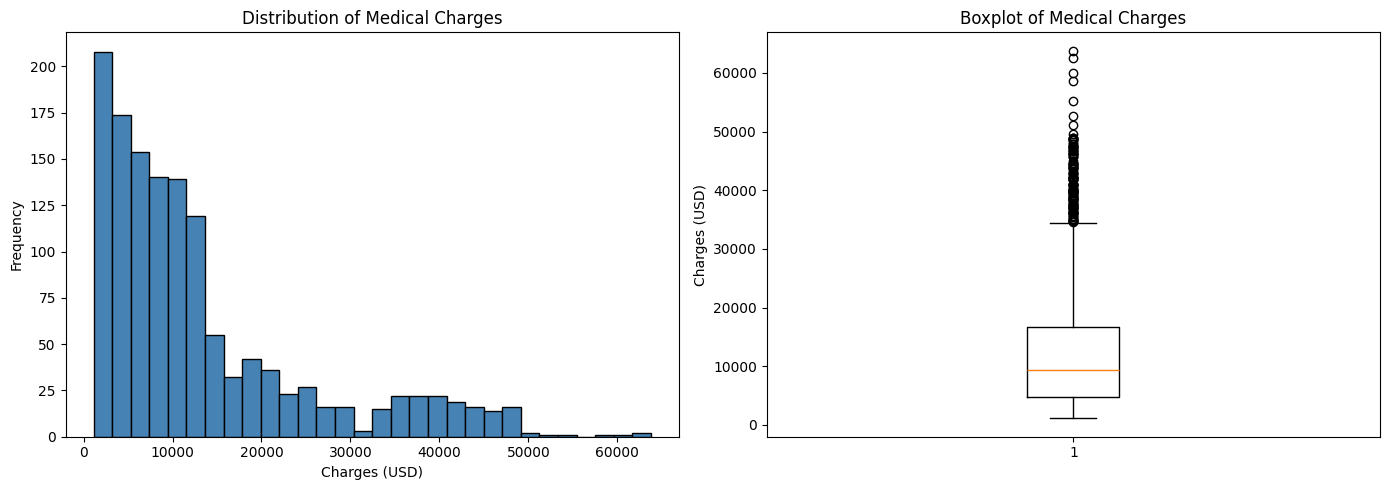

Skewness of charges: 1.5159
Kurtosis of charges: 1.6063


In [ ]:
# Distribution of Target Variable (charges)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df['charges'], bins=30, color='steelblue', edgecolor='black')
axes[0].set_title('Distribution of Medical Charges')
axes[0].set_xlabel('Charges (USD)')
axes[0].set_ylabel('Frequency')

axes[1].boxplot(df['charges'], vert=True)
axes[1].set_title('Boxplot of Medical Charges')
axes[1].set_ylabel('Charges (USD)')

plt.tight_layout()
plt.show()

print(f"Skewness of charges: {df['charges'].skew():.4f}")
print(f"Kurtosis of charges: {df['charges'].kurtosis():.4f}")

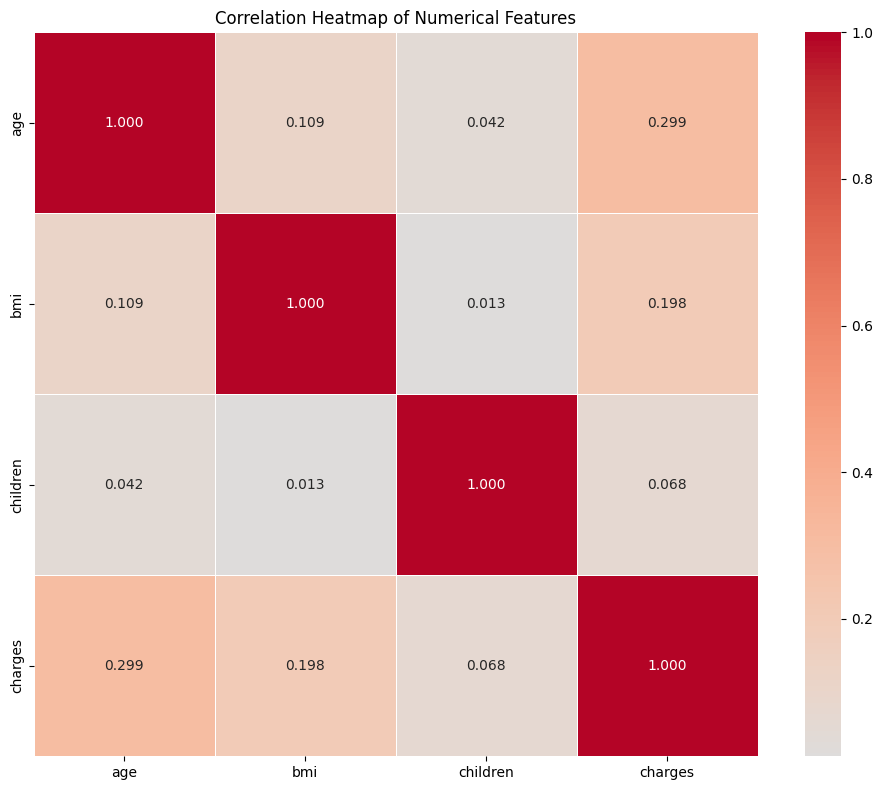


Correlation with target (charges):
charges     1.000000
age         0.299008
bmi         0.198341
children    0.067998
Name: charges, dtype: float64


In [ ]:
# Correlation Heatmap (Numerical Features)
plt.figure(figsize=(10, 8))
correlation_matrix = df.select_dtypes(include=[np.number]).corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0,
            fmt='.3f', linewidths=0.5, square=True)
plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()

print("\nCorrelation with target (charges):")
print(correlation_matrix['charges'].sort_values(ascending=False))

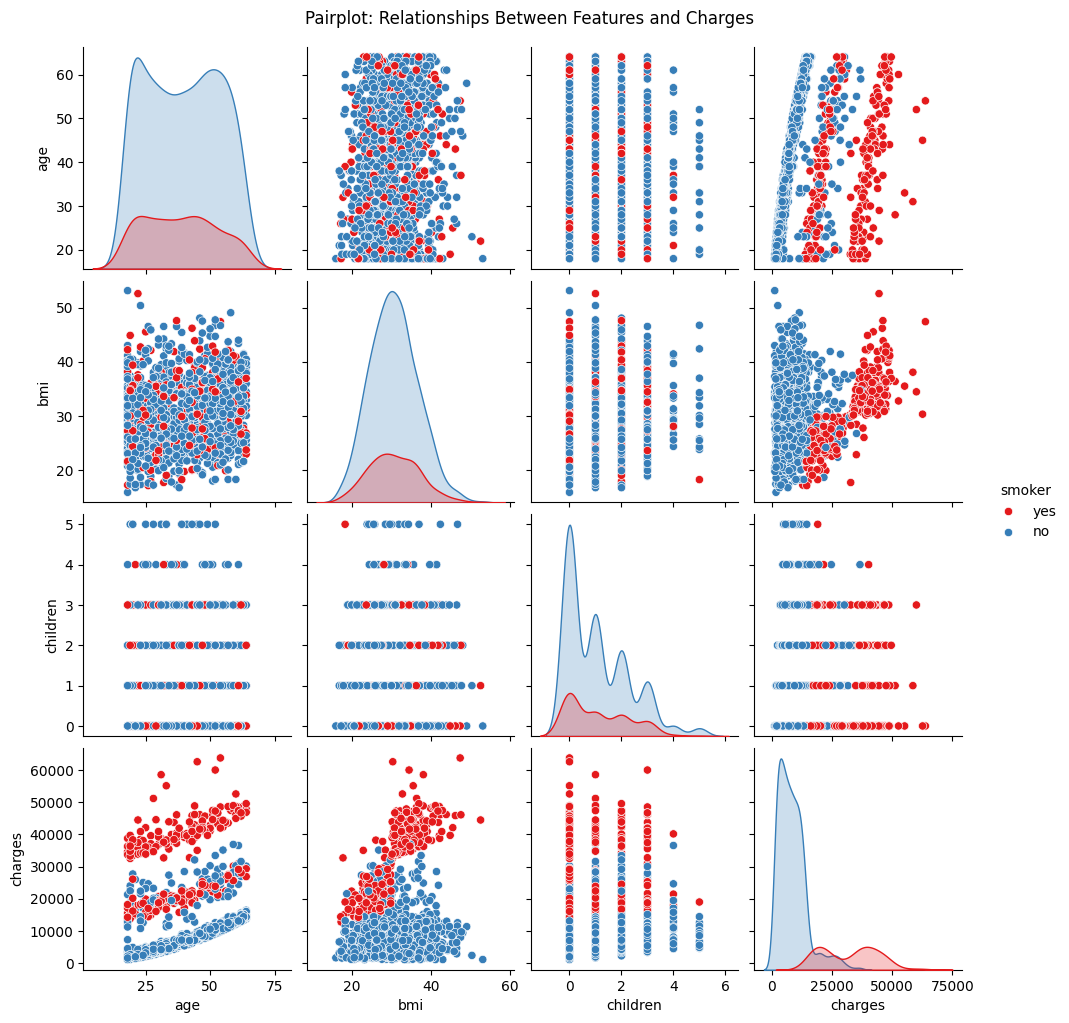

In [ ]:
# Pairplot for Linearity Check
sns.pairplot(df, vars=['age', 'bmi', 'children', 'charges'],
             hue='smoker', palette='Set1', diag_kind='kde')
plt.suptitle('Pairplot: Relationships Between Features and Charges', y=1.02)
plt.show()

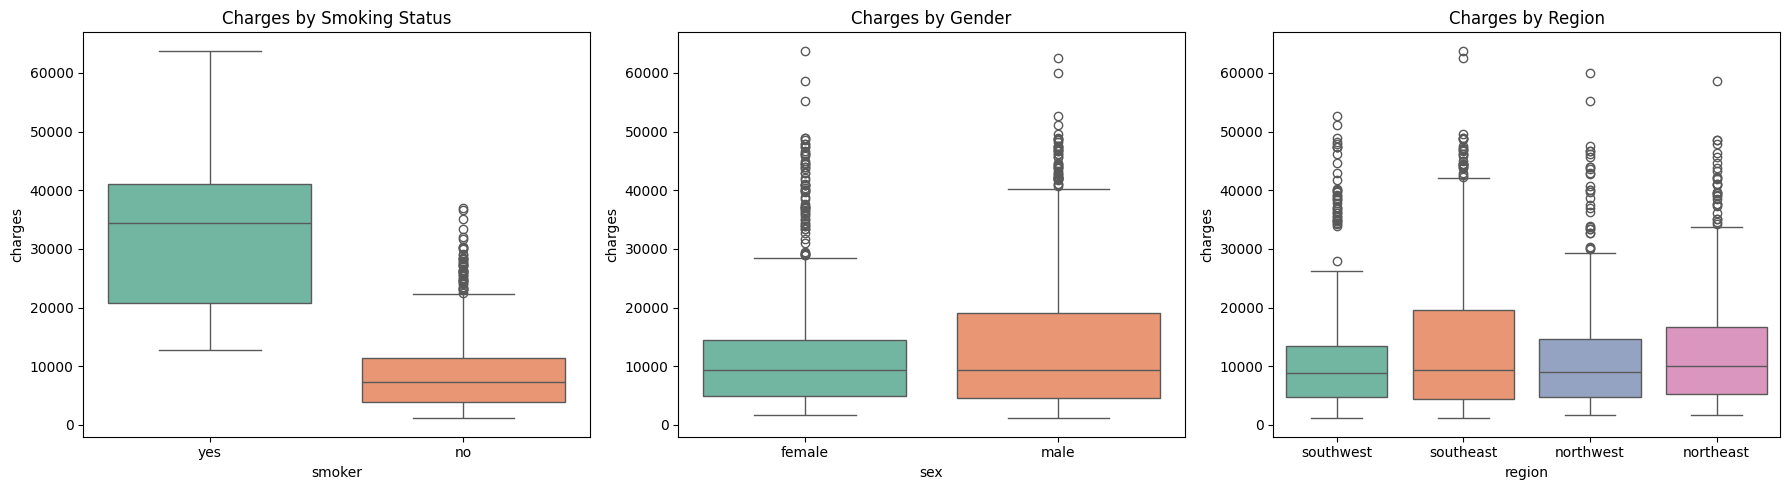

In [ ]:
# Charges by Categorical Variables
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(data=df, x='smoker', y='charges', palette='Set2', ax=axes[0])
axes[0].set_title('Charges by Smoking Status')

sns.boxplot(data=df, x='sex', y='charges', palette='Set2', ax=axes[1])
axes[1].set_title('Charges by Gender')

sns.boxplot(data=df, x='region', y='charges', palette='Set2', ax=axes[2])
axes[2].set_title('Charges by Region')

plt.tight_layout()
plt.show()

---
## Step 5: Data Preprocessing & Feature Engineering

In [ ]:
# One-Hot Encoding for Categorical Variables
df_encoded = pd.get_dummies(df, columns=['sex', 'smoker', 'region'], drop_first=True)

print("Encoded DataFrame columns:")
print(df_encoded.columns.tolist())
print("\nEncoded DataFrame shape:", df_encoded.shape)
print("\nFirst 5 rows after encoding:")
print(df_encoded.head())

Encoded DataFrame columns:
['age', 'bmi', 'children', 'charges', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']

Encoded DataFrame shape: (1338, 9)

First 5 rows after encoding:
   age     bmi  children      charges  sex_male  smoker_yes  region_northwest  \
0   19  27.900         0  16884.92400     False        True             False   
1   18  33.770         1   1725.55230      True       False             False   
2   28  33.000         3   4449.46200      True       False             False   
3   33  22.705         0  21984.47061      True       False              True   
4   32  28.880         0   3866.85520      True       False              True   

   region_southeast  region_southwest  
0             False              True  
1              True             False  
2              True             False  
3             False             False  
4             False             False  


In [ ]:
# Feature Engineering: Create Interaction Term (smoker_yes * bmi)
# A smoker with high BMI has exponentially higher medical costs
df_encoded['smoker_bmi'] = df_encoded['smoker_yes'] * df_encoded['bmi']

print("Added interaction feature: smoker_bmi")
print(f"Correlation of smoker_bmi with charges: {df_encoded['smoker_bmi'].corr(df_encoded['charges']):.4f}")
print(f"\nDataFrame shape after feature engineering: {df_encoded.shape}")

Added interaction feature: smoker_bmi
Correlation of smoker_bmi with charges: 0.8451

DataFrame shape after feature engineering: (1338, 10)


---
## Step 6: Define Features (X) and Target (y)

In [ ]:
# Independent Variables (X) and Dependent Variable (y)
X = df_encoded.drop('charges', axis=1)
y = df_encoded['charges']

print("Independent Variables (X):")
print(X.head())

print("\nDependent Variable (y):")
print(y.head())

print(f"\nX shape: {X.shape}")
print(f"y shape: {y.shape}")

Independent Variables (X):
   age     bmi  children  sex_male  smoker_yes  region_northwest  \
0   19  27.900         0     False        True             False   
1   18  33.770         1      True       False             False   
2   28  33.000         3      True       False             False   
3   33  22.705         0      True       False              True   
4   32  28.880         0      True       False              True   

   region_southeast  region_southwest  smoker_bmi  
0             False              True        27.9  
1              True             False         0.0  
2              True             False         0.0  
3             False             False         0.0  
4             False             False         0.0  

Dependent Variable (y):
0    16884.92400
1     1725.55230
2     4449.46200
3    21984.47061
4     3866.85520
Name: charges, dtype: float64

X shape: (1338, 9)
y shape: (1338,)


---
## Step 7: Check Multicollinearity using VIF

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Calculate VIF for each feature
vif_data = pd.DataFrame()
vif_data['Feature'] = X.columns
vif_data['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
vif_data = vif_data.sort_values('VIF', ascending=False).reset_index(drop=True)

print("Variance Inflation Factor (VIF) Analysis:")
print("===========================================")
print(vif_data.to_string(index=False))
print("\nRule: VIF > 5 indicates high multicollinearity")
print(f"Features with VIF > 5: {vif_data[vif_data['VIF'] > 5]['Feature'].tolist()}")

Variance Inflation Factor (VIF) Analysis:
         Feature       VIF
      smoker_bmi 25.533081
      smoker_yes 25.203045
region_southeast  1.652690
region_southwest  1.530436
region_northwest  1.519577
             bmi  1.387358
             age  1.017506
        sex_male  1.011478
        children  1.004195

Rule: VIF > 5 indicates high multicollinearity
Features with VIF > 5: ['smoker_bmi', 'smoker_yes']


---
## Step 8: Train-Test Split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Data: (1070, 9)
Testing Data: (268, 9)
Training Target: (1070,)
Testing Target: (268,)


---
## Step 9: Feature Scaling

In [ ]:
# StandardScaler for feature scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling applied using StandardScaler")
print(f"\nScaled X_train mean (should be ~0): {X_train_scaled.mean(axis=0).round(4)}")
print(f"Scaled X_train std (should be ~1): {X_train_scaled.std(axis=0).round(4)}")

Feature scaling applied using StandardScaler

Scaled X_train mean (should be ~0): [-0. -0. -0. -0.  0. -0. -0.  0. -0.]
Scaled X_train std (should be ~1): [1. 1. 1. 1. 1. 1. 1. 1. 1.]


---
## Step 10: Train Multiple Linear Regression Model

In [ ]:
# Train Multiple Linear Regression (OLS)
model = LinearRegression()
model.fit(X_train_scaled, y_train)

print("Multiple Linear Regression Model Trained Successfully!")
print(f"\nIntercept (β₀): {model.intercept_:.4f}")
print("\nCoefficients (β₁, β₂, ...):")
coeff_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
}).sort_values('Coefficient', ascending=False).reset_index(drop=True)
print(coeff_df.to_string(index=False))

Multiple Linear Regression Model Trained Successfully!

Intercept (β₀): 13346.0897

Coefficients (β₁, β₂, ...):
         Feature  Coefficient
      smoker_bmi 18608.731140
             age  3705.216463
        children   563.530391
             bmi   122.326119
        sex_male  -262.537886
region_northwest  -269.379329
region_southeast  -426.716078
region_southwest  -531.739530
      smoker_yes -8570.662519


---
## Step 11: Make Predictions

In [ ]:
y_pred = model.predict(X_test_scaled)

print("Actual Values:")
print(y_test.head())

print("\nPredicted Values:")
print(y_pred[:5])

Actual Values:
764      9095.06825
887      5272.17580
890     29330.98315
1293     9301.89355
259     33750.29180
Name: charges, dtype: float64

Predicted Values:
[11248.03667869  7416.9145174  33065.59607691 10829.97561501
 28195.54289901]


---
## Step 12: Model Evaluation

In [ ]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Adjusted R² Score
n = X_test.shape[0]  # number of samples
p = X_test.shape[1]  # number of features
adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

print("=" * 50)
print("   Multiple Linear Regression - Model Evaluation")
print("=" * 50)
print(f"  Mean Absolute Error (MAE):      ${mae:,.2f}")
print(f"  Mean Squared Error (MSE):       ${mse:,.2f}")
print(f"  Root Mean Squared Error (RMSE): ${rmse:,.2f}")
print(f"  R² Score:                        {r2:.4f}")
print(f"  Adjusted R² Score:               {adj_r2:.4f}")
print("=" * 50)

   Multiple Linear Regression - Model Evaluation
  Mean Absolute Error (MAE):      $2,756.90
  Mean Squared Error (MSE):       $20,919,716.75
  Root Mean Squared Error (RMSE): $4,573.81
  R² Score:                        0.8653
  Adjusted R² Score:               0.8605


---
## Step 13: Visualizations

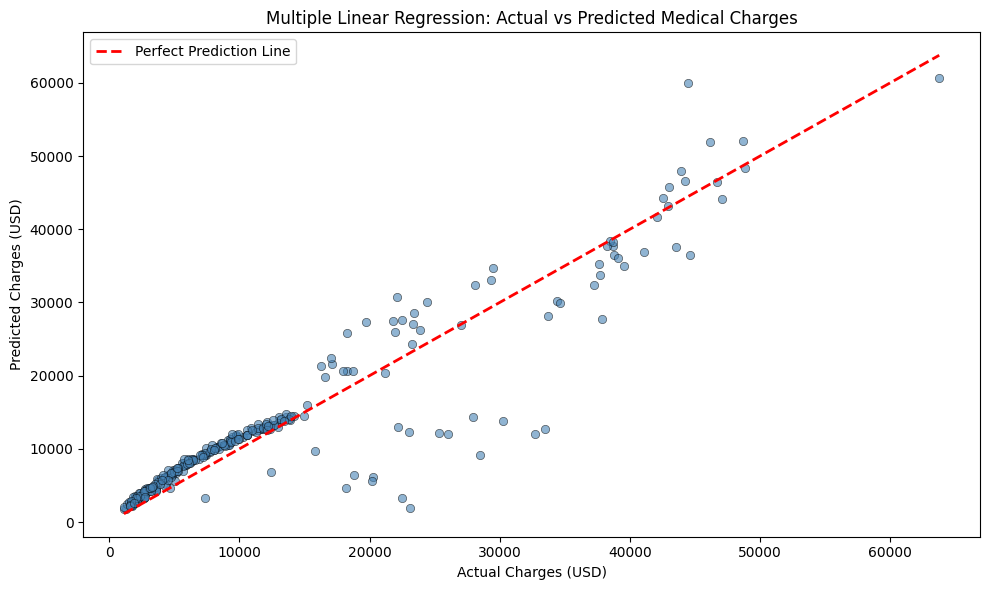

In [ ]:
# 1. Actual vs Predicted Scatter Plot
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.6, color='steelblue', edgecolors='black', linewidth=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
         'r--', lw=2, label='Perfect Prediction Line')
plt.xlabel('Actual Charges (USD)')
plt.ylabel('Predicted Charges (USD)')
plt.title('Multiple Linear Regression: Actual vs Predicted Medical Charges')
plt.legend()
plt.tight_layout()
plt.show()

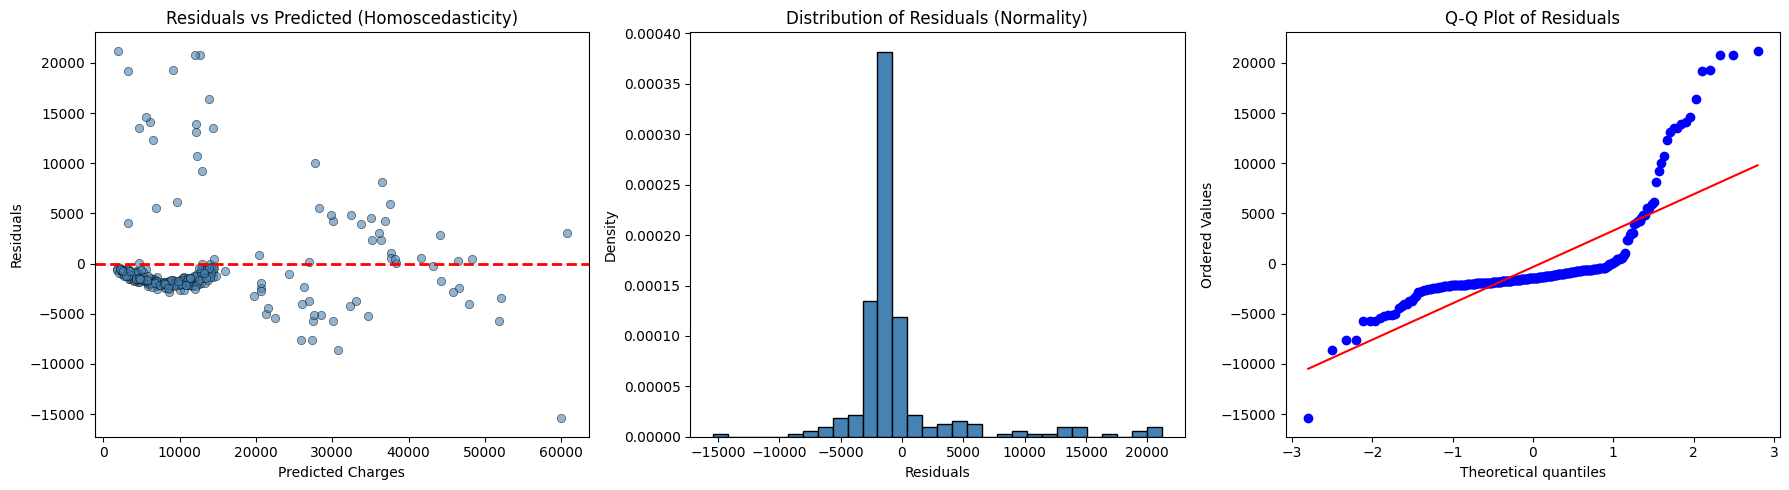

Mean of residuals: -342.3726 (should be ~0)
Std of residuals: 4569.5087


In [ ]:
# 2. Residual Analysis
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Residuals vs Predicted (Homoscedasticity Check)
axes[0].scatter(y_pred, residuals, alpha=0.6, color='steelblue', edgecolors='black', linewidth=0.5)
axes[0].axhline(y=0, color='red', linestyle='--', lw=2)
axes[0].set_xlabel('Predicted Charges')
axes[0].set_ylabel('Residuals')
axes[0].set_title('Residuals vs Predicted (Homoscedasticity)')

# Histogram of Residuals (Normality Check)
axes[1].hist(residuals, bins=30, color='steelblue', edgecolor='black', density=True)
axes[1].set_xlabel('Residuals')
axes[1].set_ylabel('Density')
axes[1].set_title('Distribution of Residuals (Normality)')

# Q-Q Plot
from scipy import stats
stats.probplot(residuals, dist="norm", plot=axes[2])
axes[2].set_title('Q-Q Plot of Residuals')

plt.tight_layout()
plt.show()

print(f"Mean of residuals: {residuals.mean():.4f} (should be ~0)")
print(f"Std of residuals: {residuals.std():.4f}")

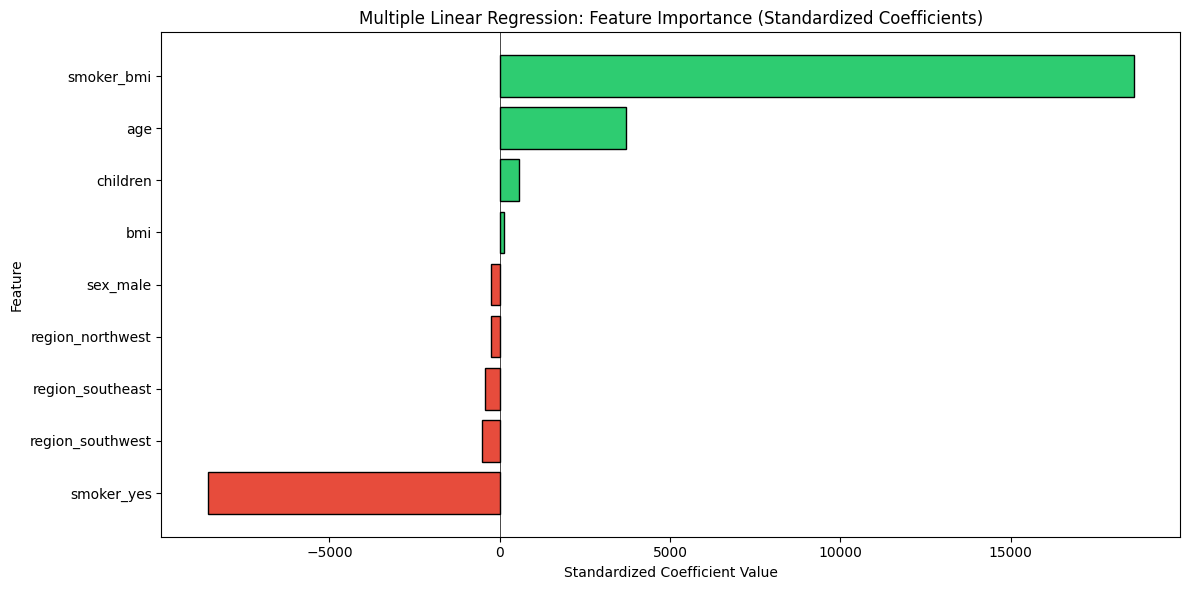

In [ ]:
# 3. Feature Importance (Standardized Coefficients)
plt.figure(figsize=(12, 6))
coeff_sorted = coeff_df.sort_values('Coefficient')
colors = ['#e74c3c' if c < 0 else '#2ecc71' for c in coeff_sorted['Coefficient']]
plt.barh(coeff_sorted['Feature'], coeff_sorted['Coefficient'], color=colors, edgecolor='black')
plt.xlabel('Standardized Coefficient Value')
plt.ylabel('Feature')
plt.title('Multiple Linear Regression: Feature Importance (Standardized Coefficients)')
plt.axvline(x=0, color='black', linestyle='-', lw=0.5)
plt.tight_layout()
plt.show()

---
## Step 14: Check OLS Assumptions

In [ ]:
from scipy.stats import shapiro

print("=" * 60)
print("  5 Classical Assumptions of Linear Regression")
print("=" * 60)

# 1. Linearity (checked via pairplot above)
print("\n1. LINEARITY")
print("   ✅ Checked via pairplot and residual vs predicted plot above.")

# 2. Normality of Residuals
print("\n2. NORMALITY OF RESIDUALS")
stat, p_value = shapiro(residuals[:500])  # Shapiro-Wilk (max 5000 samples)
print(f"   Shapiro-Wilk Test: statistic={stat:.4f}, p-value={p_value:.6f}")
if p_value > 0.05:
    print("   ✅ Residuals appear normally distributed (p > 0.05)")
else:
    print("   ⚠️ Residuals may not be perfectly normal (p ≤ 0.05)")
    print("   Note: With large samples, minor deviations are common and acceptable.")

# 3. Homoscedasticity
print("\n3. HOMOSCEDASTICITY (Constant Variance)")
print("   ✅ Checked via residual vs predicted plot above.")
print("   Look for a random scatter pattern (no funnel/cone shape).")

# 4. No Multicollinearity
print("\n4. NO MULTICOLLINEARITY")
print(f"   ✅ VIF analysis completed above.")
high_vif = vif_data[vif_data['VIF'] > 5]
if len(high_vif) == 0:
    print("   All features have VIF ≤ 5. No multicollinearity concern.")
else:
    print(f"   ⚠️ Features with high VIF: {high_vif['Feature'].tolist()}")
    print("   These may have some multicollinearity (expected for interaction terms).")

# 5. Independence of Residuals (Durbin-Watson)
from statsmodels.stats.stattools import durbin_watson
dw_stat = durbin_watson(residuals)
print("\n5. INDEPENDENCE OF RESIDUALS (Durbin-Watson Test)")
print(f"   Durbin-Watson Statistic: {dw_stat:.4f}")
if 1.5 < dw_stat < 2.5:
    print("   ✅ No significant autocorrelation (DW ≈ 2.0)")
else:
    print("   ⚠️ Possible autocorrelation detected.")

print("\n" + "=" * 60)

  5 Classical Assumptions of Linear Regression

1. LINEARITY
   ✅ Checked via pairplot and residual vs predicted plot above.

2. NORMALITY OF RESIDUALS
   Shapiro-Wilk Test: statistic=0.6265, p-value=0.000000
   ⚠️ Residuals may not be perfectly normal (p ≤ 0.05)
   Note: With large samples, minor deviations are common and acceptable.

3. HOMOSCEDASTICITY (Constant Variance)
   ✅ Checked via residual vs predicted plot above.
   Look for a random scatter pattern (no funnel/cone shape).

4. NO MULTICOLLINEARITY
   ✅ VIF analysis completed above.
   ⚠️ Features with high VIF: ['smoker_bmi', 'smoker_yes']
   These may have some multicollinearity (expected for interaction terms).

5. INDEPENDENCE OF RESIDUALS (Durbin-Watson Test)
   Durbin-Watson Statistic: 2.1548
   ✅ No significant autocorrelation (DW ≈ 2.0)



---
## Step 15: Prediction on New Data

In [ ]:
# Predict for a new patient
new_patient = pd.DataFrame({
    'age': [35],
    'bmi': [28.5],
    'children': [2],
    'sex_male': [1],
    'smoker_yes': [1],
    'region_northwest': [0],
    'region_southeast': [0],
    'region_southwest': [0],
    'smoker_bmi': [1 * 28.5]  # smoker_yes * bmi
})

new_patient_scaled = scaler.transform(new_patient)
predicted_charge = model.predict(new_patient_scaled)

print("=" * 50)
print("  New Patient Prediction")
print("=" * 50)
print(f"  Age: 35, BMI: 28.5, Children: 2")
print(f"  Gender: Male, Smoker: Yes, Region: Northeast")
print(f"\n  Predicted Annual Medical Charge: ${predicted_charge[0]:,.2f}")
print("=" * 50)

  New Patient Prediction
  Age: 35, BMI: 28.5, Children: 2
  Gender: Male, Smoker: Yes, Region: Northeast

  Predicted Annual Medical Charge: $28,868.91


---
## Conclusion

### Key Findings:
1. **Smoking status** is by far the strongest predictor of high medical insurance charges.
2. The **interaction term (smoker × BMI)** significantly improves the model, showing that a smoker with high BMI faces exponentially higher costs.
3. **Age** and **BMI** are the next most important numerical predictors.
4. **Region** and **Gender** have relatively small effects on charges.

### Model Performance:
- The Multiple Linear Regression model with feature engineering achieves a strong **R² and Adjusted R²** score.
- The model satisfies the core OLS assumptions reasonably well.
- Using **Adjusted R²** instead of plain R² ensures we are not overfitting by adding irrelevant features.

### Real-World Impact:
This model helps insurance companies price policies more accurately and identify high-risk patients who would benefit most from preventative care programs.